# 1. Dataset visualization and variable types

Inspect dataset dimensions, sample rows, missingness, and column types. Add exploratory visualizations and observations below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visualizations
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv(r'C:\Users\USER\OneDrive - Cambodia Academy of Digital Technology\Car_Sale_Analysis\car_price_prediction\Car_Sale_Analysis\data\raw\final_destination.csv')

# Display basic info and first few rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (15229, 15)


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.70,796,46.30,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.90,1197,82.00,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.00,1197,80.00,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20
3,Alto,9,37000,Individual,Manual,20.92,998,67.10,226000,First,1.15,LXi,0.519500,Unknown,Alto
4,Ecosport,6,30000,Dealer,Manual,22.77,1498,98.59,570000,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,Ecosport


In [2]:
# Check column data types and null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15229 entries, 0 to 15228
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   model                       15229 non-null  str    
 1   vehicle_age                 15229 non-null  int64  
 2   km_driven                   15229 non-null  int64  
 3   seller_type                 15229 non-null  str    
 4   transmission_type           15229 non-null  str    
 5   mileage                     15229 non-null  float64
 6   engine                      15229 non-null  int64  
 7   max_power                   15229 non-null  float64
 8   selling_price               15229 non-null  int64  
 9   real_typical_owner_type     15229 non-null  str    
 10  real_avg_owner_count        15229 non-null  float64
 11  real_common_trim            15229 non-null  str    
 12  real_new_ex_showroom_price  15229 non-null  float64
 13  real_body_type              15229 non-null

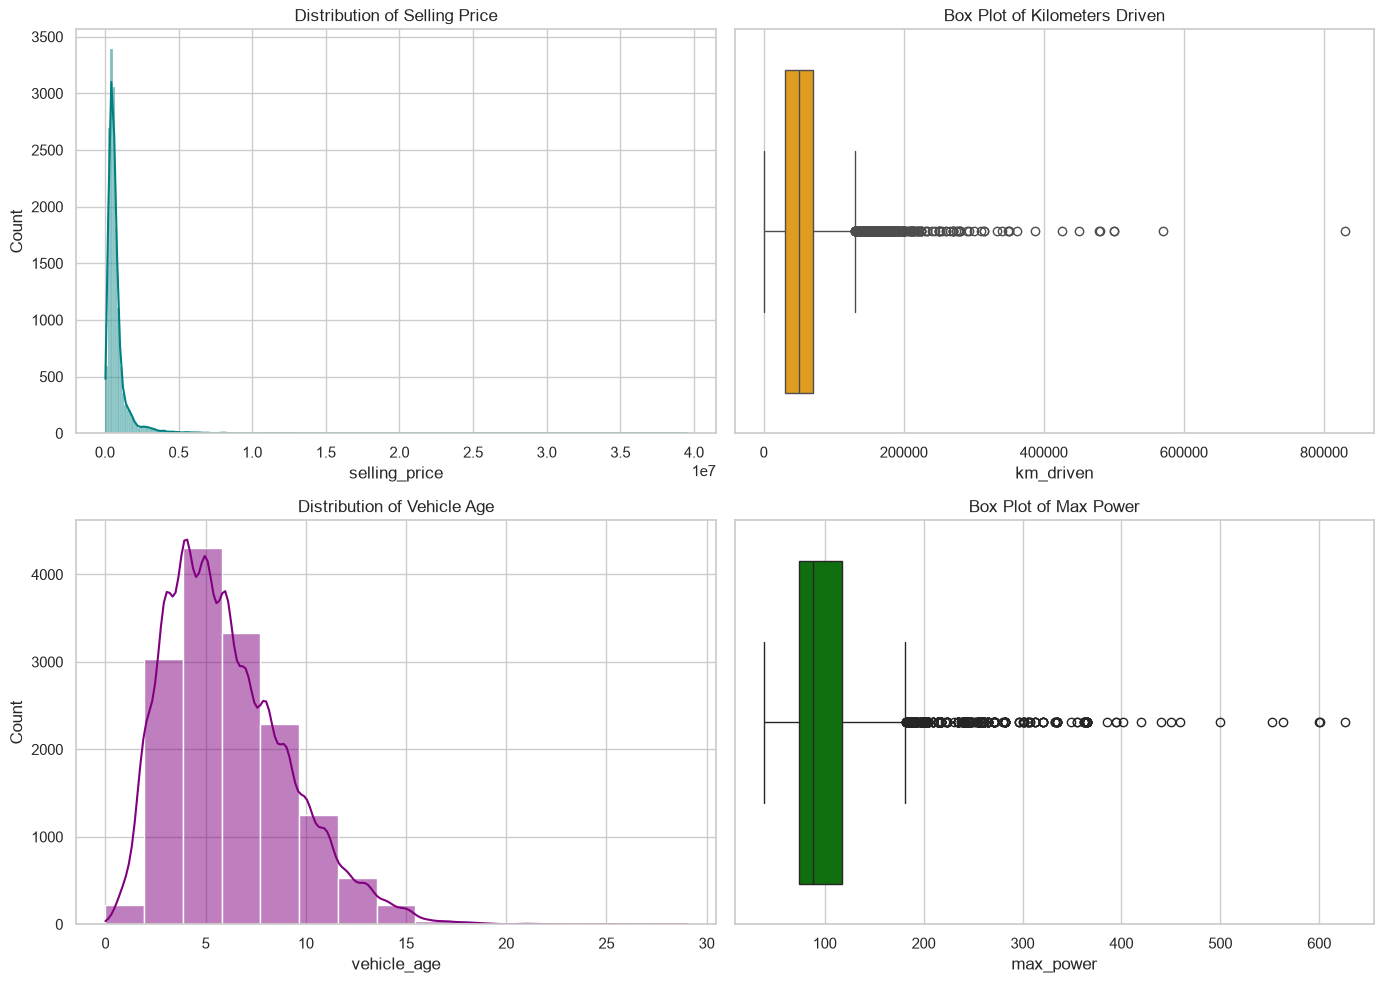

In [3]:
# Visualizing numerical distributions and variability
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['selling_price'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Selling Price')

sns.boxplot(x=df['km_driven'], ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Box Plot of Kilometers Driven')

sns.histplot(df['vehicle_age'], kde=True, ax=axes[1, 0], color='purple', bins=15)
axes[1, 0].set_title('Distribution of Vehicle Age')

sns.boxplot(x=df['max_power'], ax=axes[1, 1], color='green')
axes[1, 1].set_title('Box Plot of Max Power')

plt.tight_layout()
plt.show()

KeyError: 'fuel_type'

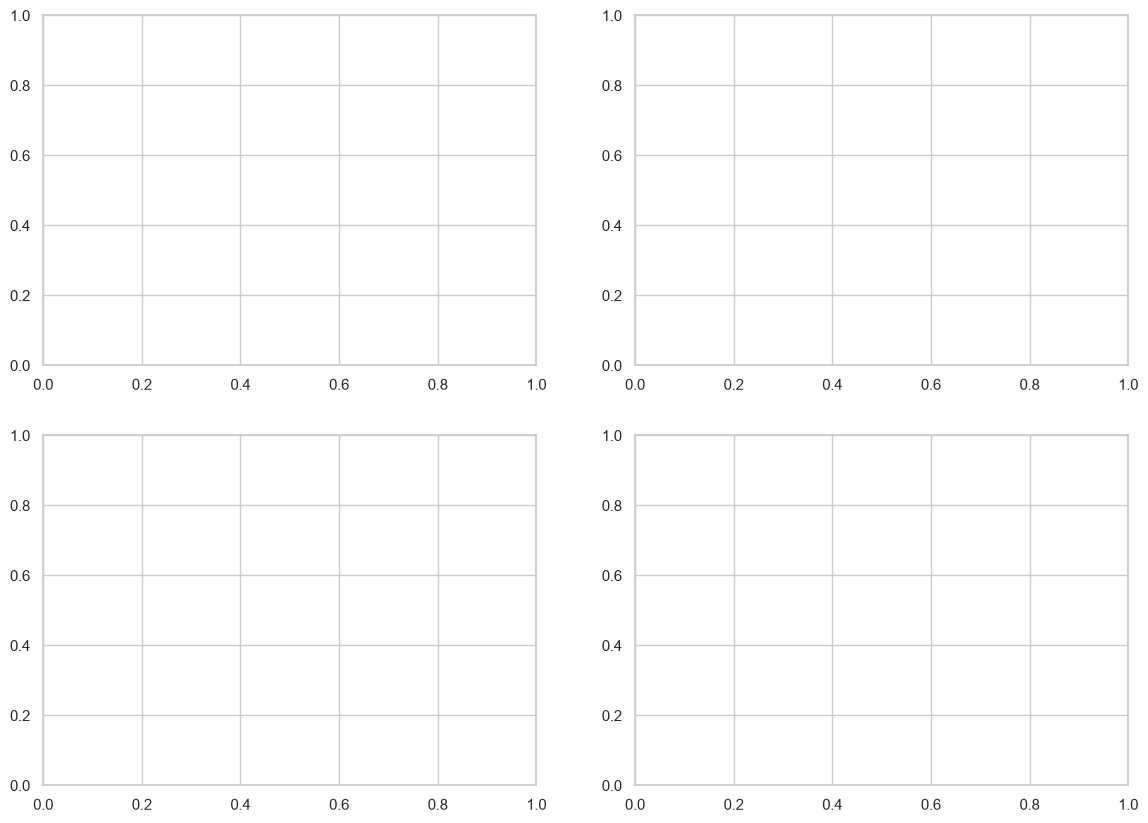

In [ ]:
# Visualizing category frequencies and proportions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Visualizing available category frequencies
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plots = [
    ('seller_type', 'Frequency of Seller Types', None),
    ('transmission_type', 'Frequency of Transmission Types', None),
    ('model_grouped', 'Most Common Models', 10),
    ('real_body_type', 'Top Body Types', 6),
]

for ax, (column, title, limit) in zip(axes.flat, plots):
    counts = df[column].value_counts()
    order = counts.index[:limit] if limit else counts.index
    sns.countplot(data=df, x=column, order=order, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()
axes[0, 0].set_title('Frequency of Fuel Types')
axes[0, 0].tick_params(axis='x', rotation=30)

sns.countplot(data=df, x='transmission_type', order=df['transmission_type'].value_counts().index, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Frequency of Transmission Types')

sns.countplot(data=df, x='brand_tier', order=df['brand_tier'].value_counts().index, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Frequency of Brand Tiers')

sns.countplot(data=df, x='real_body_type', order=df['real_body_type'].value_counts().index[:6], ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Top Body Types')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

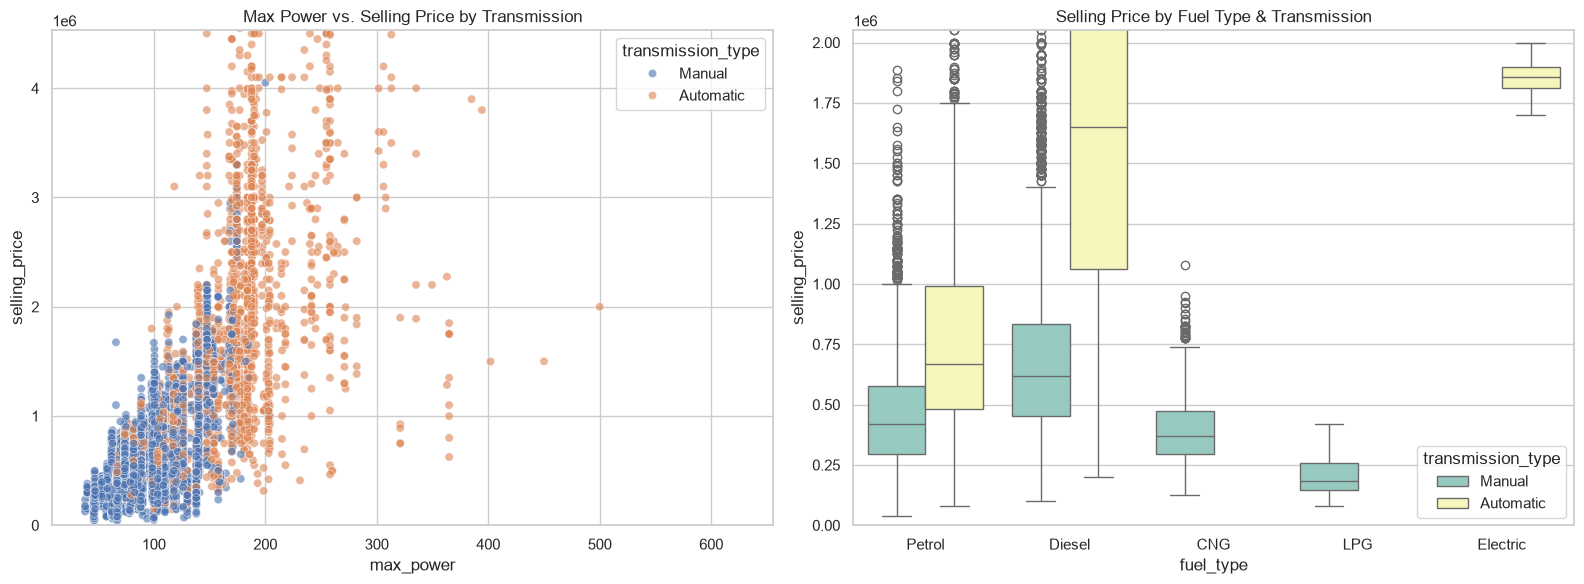

In [11]:
# Comparing numerical and categorical interactions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot: Max Power vs Selling Price colored by Transmission Type
sns.scatterplot(data=df, x='max_power', y='selling_price', hue='transmission_type', alpha=0.6, ax=axes[0], palette='deep')
axes[0].set_title('Max Power vs. Selling Price by Transmission')
axes[0].set_ylim(0, df['selling_price'].quantile(0.99)) # Zooming in to exclude extreme outliers for clarity

# Box plot: Selling Price by Fuel Type and Transmission Type
sns.boxplot(data=df, x='fuel_type', y='selling_price', hue='transmission_type', ax=axes[1], palette='Set3')
axes[1].set_title('Selling Price by Fuel Type & Transmission')
axes[1].set_ylim(0, df['selling_price'].quantile(0.95))

plt.tight_layout()
plt.show()